# Rn-222 Chain Rate Trend — 2026-08-15 → 2026-09-20

Loads `data/trend_sr3_science_full.csv` (merged P5 + P6 per-run rates for the
three Rn-222-chain isotopes: Rn-222, Po-218, Po-214).
Change `DATE_START` / `DATE_END` in the config cell to zoom.


In [58]:
# 1. Imports + load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib
from datetime import datetime, timezone, timedelta
import warnings; warnings.filterwarnings('ignore')

def safe_tight(fig=None):
    try: (fig or plt).tight_layout()
    except Exception: pass

CSV_PATH = 'data/trend_sr3_science_full.csv'
df = pd.read_csv(CSV_PATH)

print('File      : %s' % CSV_PATH)
print('Rows      : %d  |  runs: %d  |  isotopes: %d' % (
    len(df), df['run'].nunique(), df['isotope'].nunique()))
print('Isotopes  : %s' % ', '.join(sorted(df['isotope'].unique())))
print('Partitions: %s' % dict(df['partition'].value_counts()))
t_lo = pd.to_datetime(df['start_s'].min(), unit='s', utc=True)
t_hi = pd.to_datetime(df['start_s'].max(), unit='s', utc=True)
print('Date range: %s -> %s UTC' % (t_lo.strftime('%Y-%m-%d'), t_hi.strftime('%Y-%m-%d')))


File      : data/trend_sr3_science_full.csv
Rows      : 3243  |  runs: 1081  |  isotopes: 3
Isotopes  : Po-214, Po-218, Rn-222
Partitions: {'P5: POST 0708': 2034, 'P6: 0903-0920': 1209}
Date range: 2026-07-15 -> 2026-09-19 UTC


In [59]:
# 2. Quick data check — coverage per partition / isotope

summary = (df.groupby(['partition', 'isotope'])
             .agg(runs=('run', 'nunique'),
                  n_events=('n_events', 'sum'),
                  rate_median=('rate_ukgb', 'median'),
                  rate_mean=('rate_ukgb', 'mean'))
             .round(2))
print(summary.to_string())

print('\nRuns per partition:')
print(df.drop_duplicates('run')['partition'].value_counts().sort_index().to_string())

n_zero = int((df['rate_ukgb'] <= 0).sum())
print('\nRows with rate <= 0: %d (%.1f%%)' % (n_zero, 100.0 * n_zero / len(df)))


                       runs  n_events  rate_median  rate_mean
partition     isotope                                        
P5: POST 0708 Po-214    678     10682         1.14       1.38
              Po-218    678     28323         3.18       3.62
              Rn-222    678     30387         3.34       3.90
P6: 0903-0920 Po-214    403      5901         1.28       1.20
              Po-218    403     13754         2.96       2.92
              Rn-222    403     14501         3.11       3.08

Runs per partition:
partition
P5: POST 0708    678
P6: 0903-0920    403

Rows with rate <= 0: 20 (0.6%)


In [60]:
# 3. Configuration — change these to zoom
DATE_START = '2026-08-15'      # science window start
DATE_END   = '2026-09-20'      # exclusive
PEAK_NAMES = ['Rn-222', 'Po-218', 'Po-214']  # Rn-222 chain (5.59 / 6.115 / 7.834 MeV)
N_PEAKS = len(PEAK_NAMES)

# Partition boundaries (black solid) + secondary events (gray dashed)
PART_VLINES = [
    ('2026-09-03', 'P6: 0903-0920', 'black', '-'),
]
EVENT_VLINES = []

In [61]:
# 3. Helper — draw vlines (only within visible x range)
def add_vlines(ax):
    x0, x1 = ax.get_xlim()
    for date_str, label, color, ls in PART_VLINES + EVENT_VLINES:
        dt = datetime.strptime(date_str, "%Y-%m-%d").replace(tzinfo=timezone.utc)
        dn = mdates.date2num(dt)
        if dn < x0 or dn > x1: continue  # skip vlines outside visible range
        lw = 1.2 if color == "black" else 0.8
        ax.axvline(x=dt, color=color, ls=ls, lw=lw, alpha=0.5)
        y_top = ax.get_ylim()[1]
        yt = y_top * 0.93 if color == "black" else y_top * 0.82
        fs = 7 if color == "black" else 6
        ax.text(dt, yt, label, fontsize=fs, color=color, rotation=90, va="top", ha="right", alpha=0.8)


In [62]:
# 4. Filter by date range
df_view = df
if DATE_START:
    ts = pd.Timestamp(DATE_START, tz='UTC').timestamp()
    df_view = df_view[df_view['start_s'] >= ts]
if DATE_END:
    te = pd.Timestamp(DATE_END, tz='UTC').timestamp()
    df_view = df_view[df_view['start_s'] < te]
ds = DATE_START or 'start'
de = DATE_END or 'end'
print('Date range: %s -> %s (%d rows, %d runs)' % (ds, de, len(df_view), df_view['run'].nunique()))


Date range: 2026-08-15 -> 2026-09-20 (2163 rows, 721 runs)


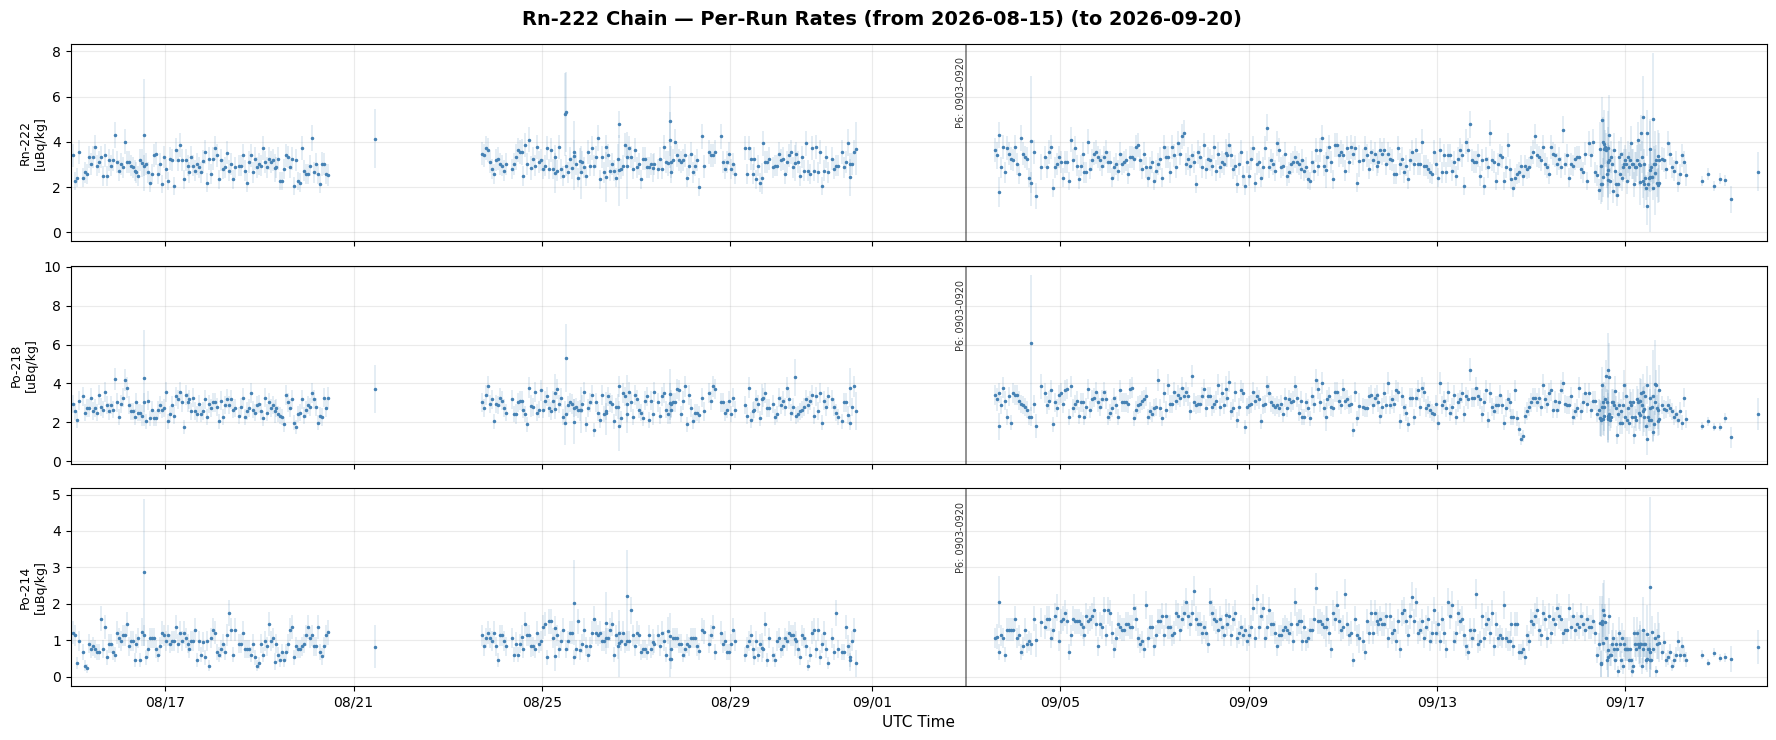

In [63]:
# 5. Per-run scatter — one panel per isotope
fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]

for ax, name in zip(axes, PEAK_NAMES):
    di = df_view[(df_view["isotope"] == name) & (df_view["rate_ukgb"] > 0)]
    if len(di) == 0: continue
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di["start_s"]]
    ax.errorbar(np.array(sd), di["rate_ukgb"].values, yerr=di["rate_err_ukgb"].values,
                fmt="o", color="steelblue", markersize=1.5, capsize=0, lw=0.2)
    ax.set_ylabel("%s\n[uBq/kg]" % name, fontsize=9)
    ax.grid(True, alpha=0.25)
    add_vlines(ax)

# Zoom: set xlim from DATE_START/END (data already filtered in cell 4)
t0 = datetime.strptime((DATE_START or "2026-05-01"), "%Y-%m-%d").replace(tzinfo=timezone.utc)
t1 = datetime.strptime((DATE_END   or "2026-07-02"), "%Y-%m-%d").replace(tzinfo=timezone.utc)
axes[-1].set_xlim(t0, t1)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d", tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel("UTC Time", fontsize=11)
fig.autofmt_xdate(rotation=0, ha="center")
title = "Rn-222 Chain — Per-Run Rates"
if DATE_START: title += " (from %s)" % DATE_START
if DATE_END: title += " (to %s)" % DATE_END
fig.suptitle(title, fontsize=14, fontweight="bold")
safe_tight(fig); plt.show()


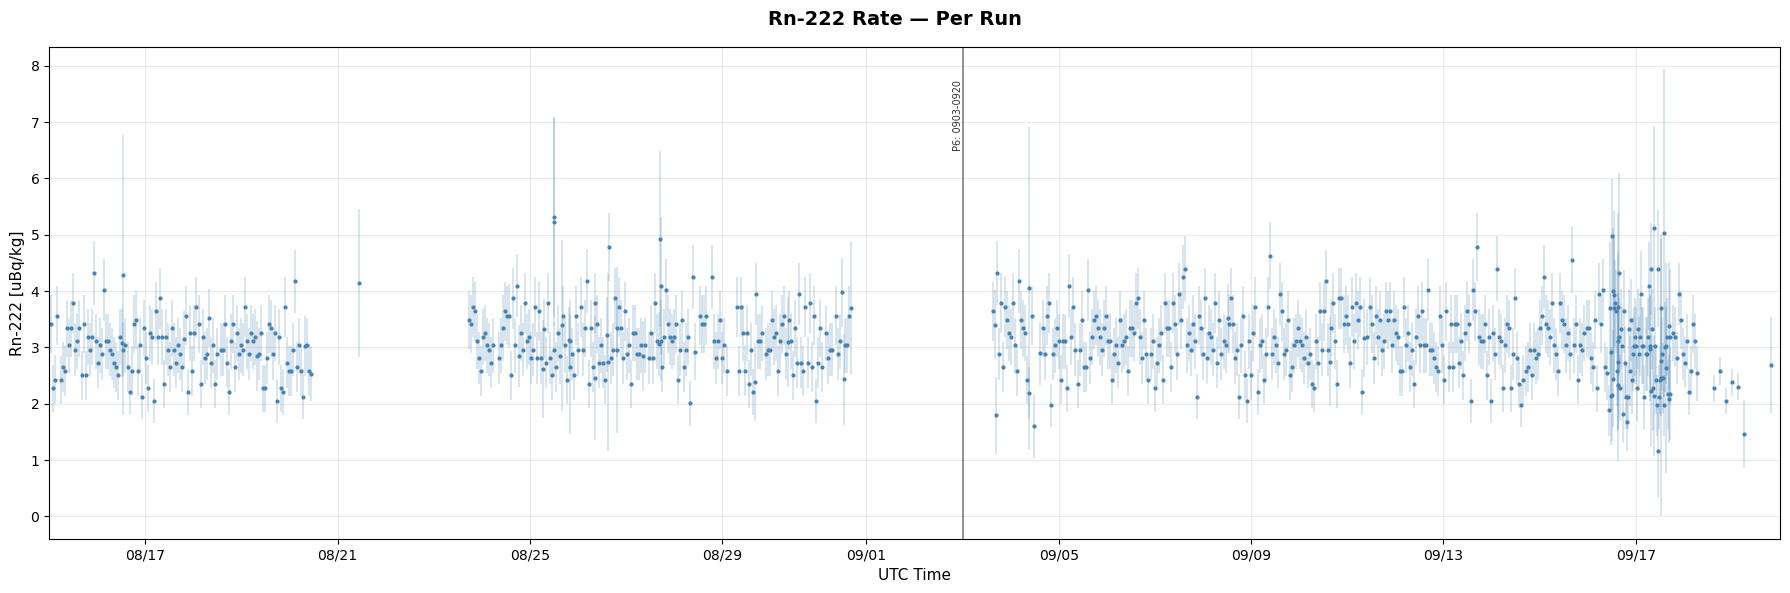

In [64]:
# 6. Rn-222 only — single-panel zoom
fig, ax = plt.subplots(figsize=(18, 6))
name = 'Rn-222'
di = df_view[(df_view['isotope'] == name) & (df_view['rate_ukgb'] > 0)]
if len(di):
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=2, capsize=0, lw=0.3)
ax.set_ylabel('%s [uBq/kg]' % name, fontsize=11)
ax.grid(True, alpha=0.25)
add_vlines(ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
t0 = datetime.strptime((DATE_START or "2026-05-01"), "%Y-%m-%d").replace(tzinfo=timezone.utc)
t1 = datetime.strptime((DATE_END   or "2026-07-02"), "%Y-%m-%d").replace(tzinfo=timezone.utc)
ax.set_xlim(t0, t1)
ax.set_xlim(t0, t1)
fig.suptitle('Rn-222 Rate — Per Run', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


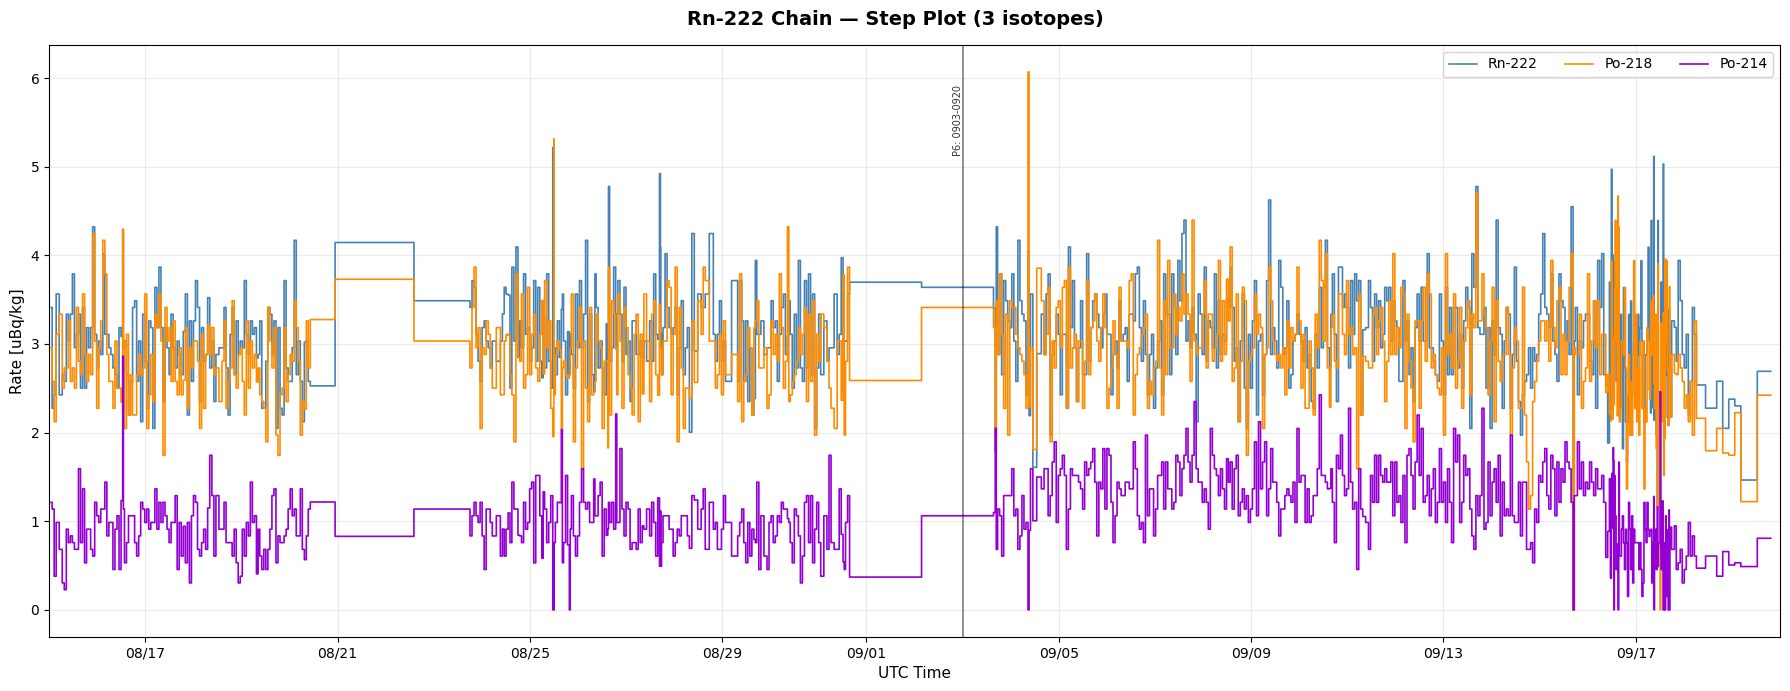

In [65]:
# 7. Step plot — three Rn-222-chain isotopes

STEP_COLORS = {'Rn-222': 'steelblue', 'Po-218': 'darkorange', 'Rn-220': 'seagreen', 'Po-216': 'firebrick', 'Po-214': 'darkviolet'}

fig, ax = plt.subplots(figsize=(18, 7))
for name in PEAK_NAMES:
    di = df_view[df_view['isotope'] == name].sort_values('start_s')
    if len(di) == 0: continue
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.step(sd, di['rate_ukgb'].values, where='mid', color=STEP_COLORS[name], lw=1.2, label=name)

add_vlines(ax)
ax.set_xlim(t0, t1)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=10, loc='upper right', ncol=3)
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Rn-222 Chain — Step Plot (3 isotopes)', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


Po-218 / Rn-222: mean = 0.9496 +- 0.1742 (705 runs)
Po-214 / Rn-222: mean = 0.3680 +- 0.1440 (705 runs)


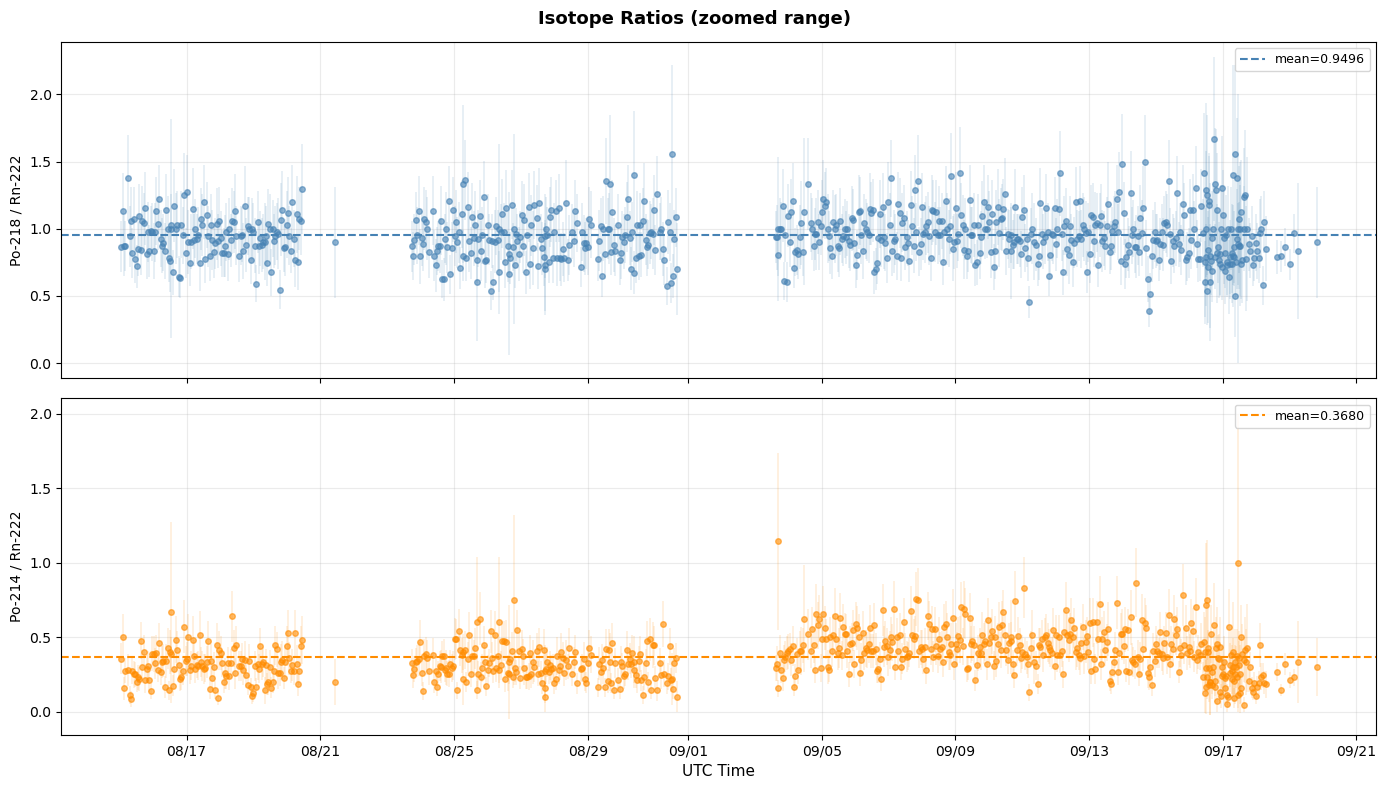

In [66]:
# 8. Po-218/Rn-222 and Po-214/Rn-222 ratios for zoomed range

# Pivot: one row per run, columns = isotope rates
piv = df_view.pivot_table(index=['run', 'start_s'], columns='isotope', values='rate_ukgb').reset_index()
# Drop runs where any of the three isotopes has zero or NaN
piv = piv.dropna(subset=['Rn-222', 'Po-218', 'Po-214'])
piv = piv[(piv['Rn-222'] > 0) & (piv['Po-218'] > 0) & (piv['Po-214'] > 0)]

# Compute ratios with error propagation
for iso, rcol in [('Po-218', 'ratio_218_222'), ('Po-214', 'ratio_214_222')]:
    piv[rcol] = piv[iso] / piv['Rn-222']
    # Propagate error: delta_r = r * sqrt((de_A/A)^2 + (de_B/B)^2)
    # Using the error from the original df_view (we need to look it up)

# Look up errors from df_view and propagate
def get_err(df, run, isotope):
    m = (df['run'] == run) & (df['isotope'] == isotope)
    return df.loc[m, 'rate_err_ukgb'].values[0] if m.any() else np.nan

ratios_218 = []
ratios_214 = []
for _, row in piv.iterrows():
    rn_rate = row['Rn-222']
    rn_err  = get_err(df_view, row['run'], 'Rn-222')
    d218 = row['Po-218'] / rn_rate
    d214 = row['Po-214'] / rn_rate
    e218 = d218 * np.sqrt((get_err(df_view, row['run'], 'Po-218')/row['Po-218'])**2 + (rn_err/rn_rate)**2) if rn_err else np.nan
    e214 = d214 * np.sqrt((get_err(df_view, row['run'], 'Po-214')/row['Po-214'])**2 + (rn_err/rn_rate)**2) if rn_err else np.nan
    ratios_218.append((d218, e218))
    ratios_214.append((d214, e214))

piv['ratio_218_222_err'] = [r[1] for r in ratios_218]
piv['ratio_214_222_err'] = [r[1] for r in ratios_214]

mean_218 = piv['ratio_218_222'].mean()
mean_214 = piv['ratio_214_222'].mean()
print('Po-218 / Rn-222: mean = %.4f +- %.4f (%d runs)' % (mean_218, piv['ratio_218_222'].std(), len(piv)))
print('Po-214 / Rn-222: mean = %.4f +- %.4f (%d runs)' % (mean_214, piv['ratio_214_222'].std(), len(piv)))

# Plot with error bars
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in piv['start_s']]

ax1.errorbar(sd, piv['ratio_218_222'], yerr=piv['ratio_218_222_err'],
             fmt='o', color='steelblue', markersize=4, capsize=0, lw=0.3, alpha=0.6)
ax1.axhline(mean_218, color='steelblue', ls='--', lw=1.5, label='mean=%.4f' % mean_218)
ax1.set_ylabel('Po-218 / Rn-222', fontsize=10)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.25)

ax2.errorbar(sd, piv['ratio_214_222'], yerr=piv['ratio_214_222_err'],
             fmt='o', color='darkorange', markersize=4, capsize=0, lw=0.3, alpha=0.6)
ax2.axhline(mean_214, color='darkorange', ls='--', lw=1.5, label='mean=%.4f' % mean_214)
ax2.set_ylabel('Po-214 / Rn-222', fontsize=10)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.25)

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
ax2.set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Isotope Ratios (zoomed range)', fontsize=13, fontweight='bold')
safe_tight(fig); plt.show()


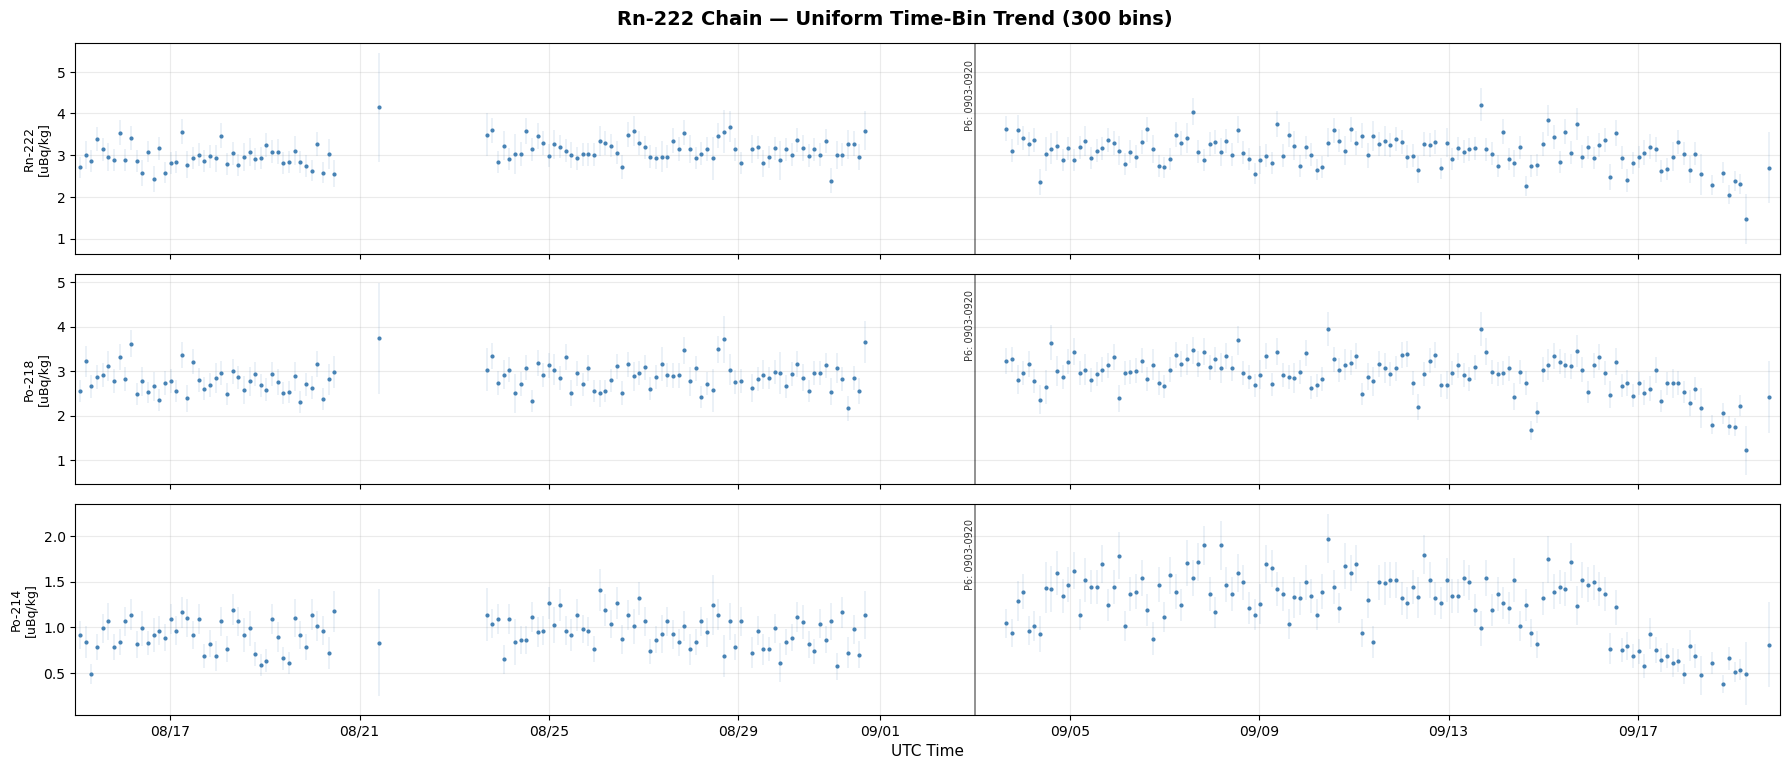

In [67]:
# 9. Uniform time-bin trend (N_BINS_TREND bins) — from per-run n_events + livetime

N_BINS_TREND = 300
FMASS = 3660.0

t_first = df_view['start_s'].min()
t_last  = df_view['end_s'].max()
edges   = np.linspace(t_first, t_last, N_BINS_TREND + 1)
centers = 0.5 * (edges[:-1] + edges[1:])

def bin_rate(sub):
    n = np.zeros(N_BINS_TREND); lt = np.zeros(N_BINS_TREND)
    if len(sub) > 0:
        idx = np.clip(np.digitize(sub['start_s'].values, edges) - 1, 0, N_BINS_TREND - 1)
        np.add.at(n, idx, sub['n_events'].values)
        np.add.at(lt, idx, sub['livetime_s'].values)
    ok = lt > 0
    rate = np.full(N_BINS_TREND, np.nan); err = np.full(N_BINS_TREND, np.nan)
    rate[ok] = n[ok] / lt[ok] * 1e6 / FMASS
    err[ok]  = np.sqrt(np.maximum(n[ok], 1)) / lt[ok] * 1e6 / FMASS
    return rate, err

fig, axes = plt.subplots(len(PEAK_NAMES), 1, figsize=(18, 2.6*len(PEAK_NAMES)), sharex=True)
if len(PEAK_NAMES) == 1: axes = [axes]
sd = np.array([datetime.fromtimestamp(s, tz=timezone.utc) for s in centers])
for ax, name in zip(axes, PEAK_NAMES):
    sub = df_view[df_view['isotope'] == name]
    rate, err = bin_rate(sub)
    ax.errorbar(sd, rate, yerr=err, fmt='o', color='steelblue',
                markersize=2, capsize=0, lw=0.15)
    ax.set_ylabel('%s\n[uBq/kg]' % name, fontsize=9)
    ax.grid(True, alpha=0.25)
    add_vlines(ax)

t0 = datetime.strptime((DATE_START or '2026-05-01'), '%Y-%m-%d').replace(tzinfo=timezone.utc)
t1 = datetime.strptime((DATE_END   or '2026-07-08'), '%Y-%m-%d').replace(tzinfo=timezone.utc)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
axes[-1].set_xlim(t0, t1)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Rn-222 Chain — Uniform Time-Bin Trend (%d bins)' % N_BINS_TREND,
             fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


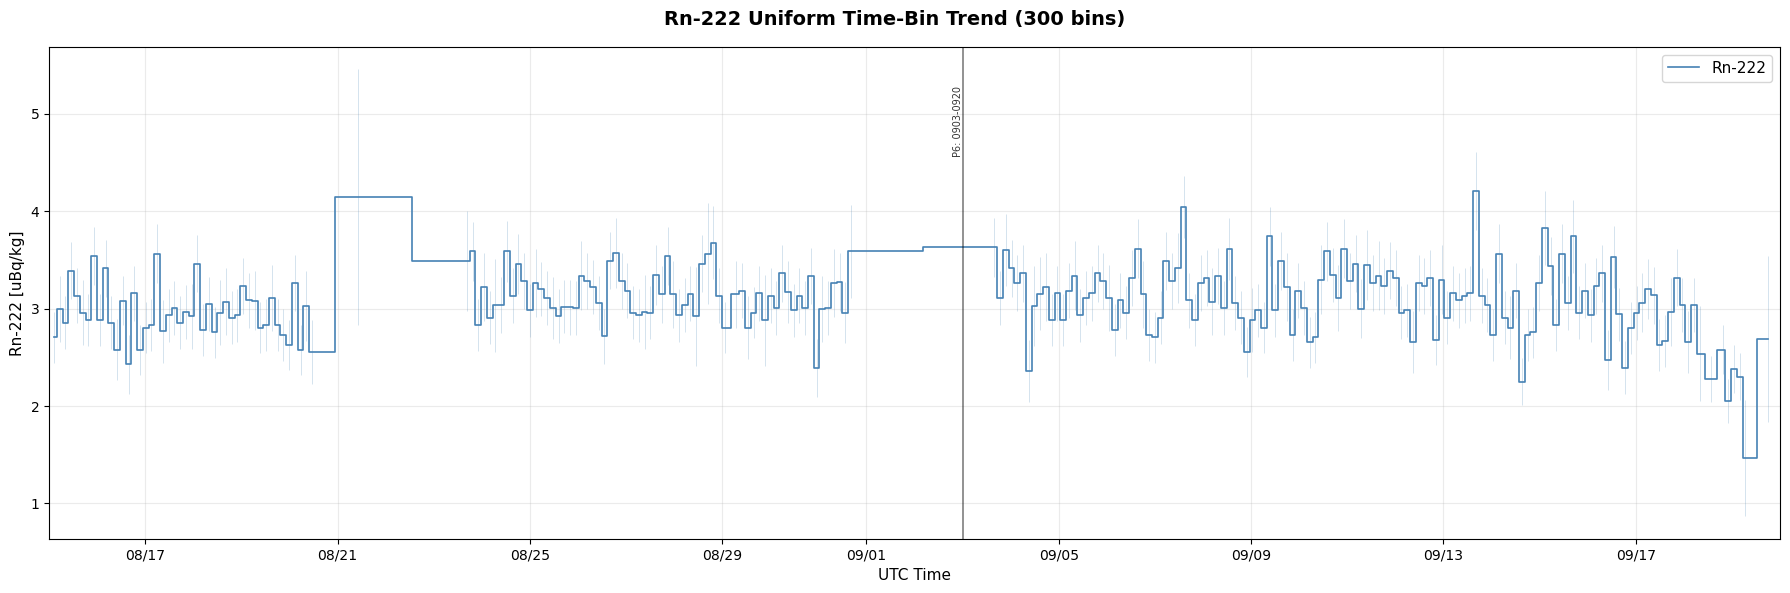

In [68]:
# 10. Rn-222 uniform time-bin step (N_BINS_TREND bins, combined, continuous)

fig, ax = plt.subplots(figsize=(18, 6))
name = 'Rn-222'
rate, err = bin_rate(df_view[df_view['isotope'] == name])
m = np.isfinite(rate)                       # skip empty bins -> continuous step
ax.step(sd[m], rate[m], where='mid', color='steelblue', lw=1.2, label=name)
ax.errorbar(sd[m], rate[m], yerr=err[m], fmt='none', ecolor='steelblue', alpha=0.4, lw=0.4)
add_vlines(ax)
ax.set_ylabel('%s [uBq/kg]' % name, fontsize=11)
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
ax.set_xlim(t0, t1)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Rn-222 Uniform Time-Bin Trend (%d bins)' % N_BINS_TREND,
             fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


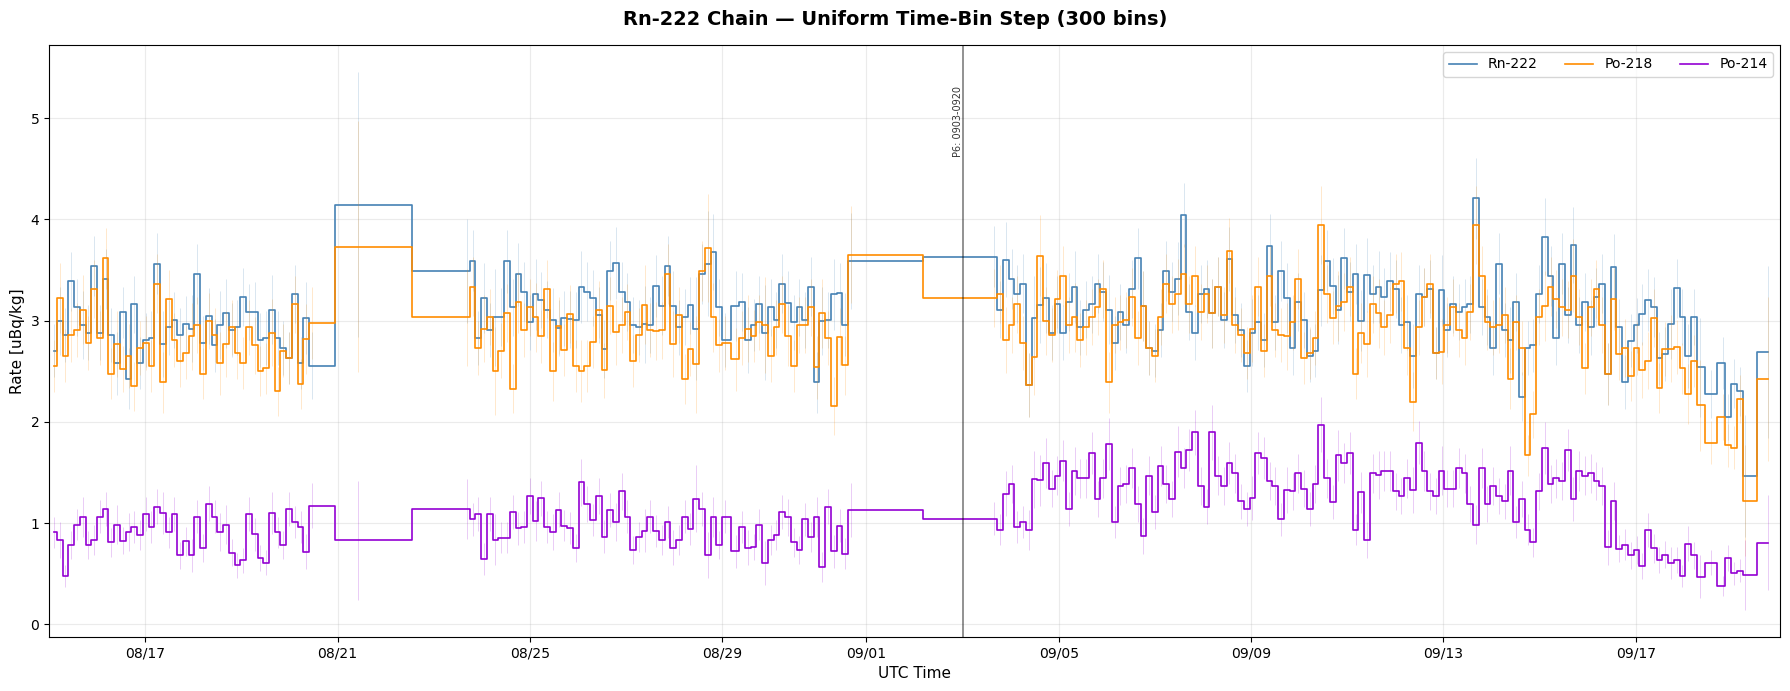

In [70]:
# 10b. Uniform time-bin step — all three isotopes together

fig, ax = plt.subplots(figsize=(18, 7))
for name in PEAK_NAMES:
    rate, err = bin_rate(df_view[df_view['isotope'] == name])
    m = np.isfinite(rate)
    ax.step(sd[m], rate[m], where='mid', color=STEP_COLORS[name], lw=1.2, label=name)
    ax.errorbar(sd[m], rate[m], yerr=err[m], fmt='none',
                ecolor=STEP_COLORS[name], alpha=0.35, lw=0.4)

add_vlines(ax)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=10, loc='upper right', ncol=3)
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
ax.set_xlim(t0, t1)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Rn-222 Chain — Uniform Time-Bin Step (%d bins)' % N_BINS_TREND,
             fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


Po-218 / Rn-222: mean = 0.9396 (0.0968 std, 245 bins)
Po-214 / Rn-222: mean = 0.3592 (0.1017 std, 245 bins)


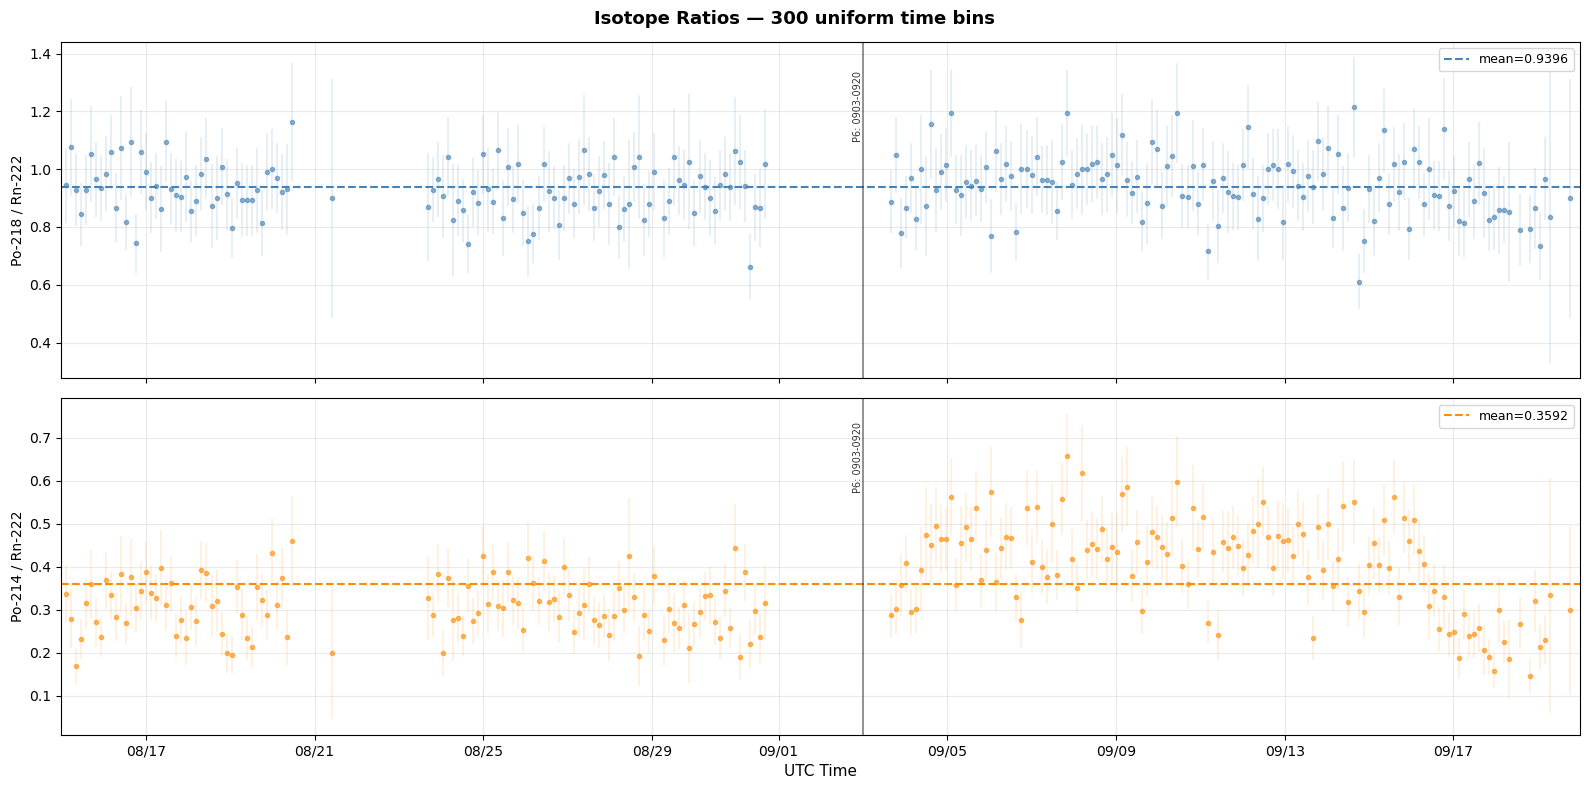

In [69]:
# 11. Isotope ratios in N_BINS_TREND uniform time bins (combined)

rn,   rn_e   = bin_rate(df_view[df_view['isotope'] == 'Rn-222'])
r218, e218   = bin_rate(df_view[df_view['isotope'] == 'Po-218'])
r214, e214   = bin_rate(df_view[df_view['isotope'] == 'Po-214'])

def _ratio(a, ea, b, eb):
    r  = a / b
    er = r * np.sqrt((ea / a)**2 + (eb / b)**2)
    return r, er

ratio218, eratio218 = _ratio(r218, e218, rn, rn_e)
ratio214, eratio214 = _ratio(r214, e214, rn, rn_e)
ok = np.isfinite(ratio218) & np.isfinite(ratio214)
print('Po-218 / Rn-222: mean = %.4f (%.4f std, %d bins)' % (
    np.nanmean(ratio218[ok]), np.nanstd(ratio218[ok]), ok.sum()))
print('Po-214 / Rn-222: mean = %.4f (%.4f std, %d bins)' % (
    np.nanmean(ratio214[ok]), np.nanstd(ratio214[ok]), ok.sum()))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, val, err, lab, col in [(ax1, ratio218, eratio218, 'Po-218 / Rn-222', 'steelblue'),
                               (ax2, ratio214, eratio214, 'Po-214 / Rn-222', 'darkorange')]:
    ax.errorbar(sd[ok], val[ok], yerr=err[ok], fmt='o', color=col,
                markersize=3, capsize=0, lw=0.3, alpha=0.6)
    mean = np.nanmean(val[ok])
    ax.axhline(mean, color=col, ls='--', lw=1.5, label='mean=%.4f' % mean)
    ax.set_ylabel(lab, fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.25)
    add_vlines(ax)

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
ax2.set_xlabel('UTC Time', fontsize=11)
ax2.set_xlim(t0, t1)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Isotope Ratios \u2014 %d uniform time bins' % N_BINS_TREND, fontsize=13, fontweight='bold')
safe_tight(fig); plt.show()
